In [6]:
import numpy as np
import cmath, math
from numpy import linalg as lin
import matplotlib.pyplot as plt
from scipy import linalg
from scipy.linalg import logm, expm

# Define constants

In [9]:
hbar = 6.626e-34/(2*np.pi)
m = 9.11e-31

# Define our well

In [12]:
a = 1e-6 # width of the well
x0 = a/2 #centre of the well
N = 10 # number of levels to truncate to
x = np.arange(0,a,5e-9)

# Calculate the eigenenergies of the stationary states

In [13]:
# Calculate the eigenenergies of the bound states
En = np.zeros(N)
for n in range(N):
    En[n] = ((n+1)*np.pi*hbar)**2/(2*m*a**2)

# Calculate the stationary states

In [14]:
H = np.zeros((N,N))
phi_n = np.zeros((N,len(x)))
for n in range(N):
    H[n,n] = En[n]
    for i in range(len(x)):
        phi_n[n][i] = np.sqrt(2/a)*np.sin((n+1)*np.pi*x[i]/a)

Text(0.5, 1.0, 'State 0')

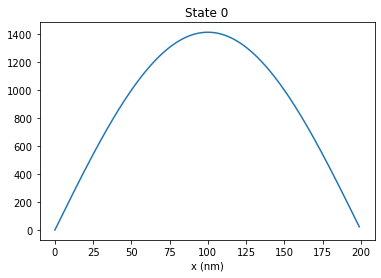

In [36]:
k=0
plt.plot(phi_n[k])
plt.xlabel('x (nm)')
plt.title(f'State {k}')

Text(0.5, 1.0, 'States N=0-10')

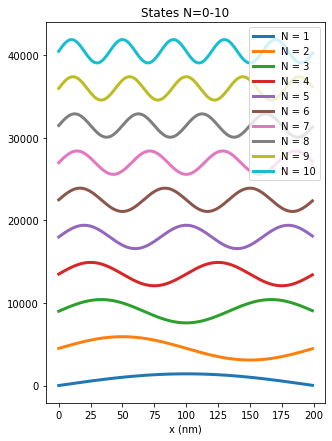

In [33]:
plt.figure(figsize=(5,7))
for k in range(10):
    plt.plot(phi_n[k] + k*4500, label=f'N = {k+1}', lw=3)
plt.legend()
plt.xlabel('x (nm)')
plt.title('States N=0-10')

# Time evolution

## Initialise our system

In [90]:
# Pre-allocate arrays
psi0 = np.zeros(len(x),dtype=np.complex64)
c_n = np.zeros(N,dtype=np.complex64)

#initial state
# c_n[0] = 1
c_n[0:2] = 1
# c_n[-2:] = 1
# c_n[0::2] = 1
# c_n = np.ones(N,dtype=np.complex64)
c_n = c_n/np.linalg.norm(c_n)

for n in range(N):
    psi0 = psi0 + c_n[n]*phi_n[n,:] 

Text(0.5, 0, 'x (nm)')

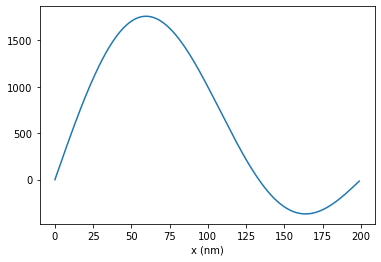

In [91]:
plt.plot(np.real(psi0))
plt.xlabel('x (nm)')

## Perform time evolution

In [92]:
time = np.arange(0,1e-8,1e-11)
psi_t = np.zeros((len(time),len(x)),dtype=np.complex64)
c_t = np.zeros((N,len(time)),dtype=np.complex64)

In [98]:
for time_idx in range(0,len(time)):
    U = expm(-1j*H*time[time_idx]/hbar) #H was defined above 
    c_t[:,time_idx] = c_n @ U
    psi_t[time_idx,:] = c_t[:,time_idx].T @ phi_n

Text(0, 0.5, 'Time')

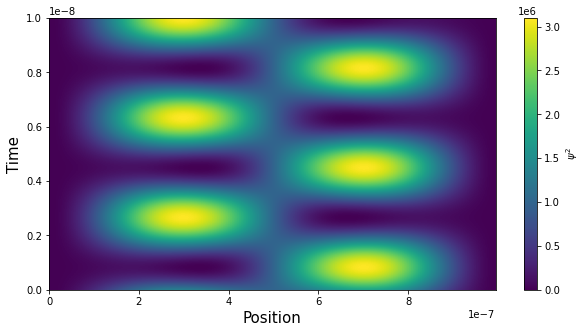

In [99]:
plt.figure(figsize=[10,5])
plt.imshow(np.square(np.abs(psi_t)),aspect='auto', extent=(np.min(x), np.max(x), np.min(time), np.max(time)))
plt.colorbar(label='$\psi^{2}$')
plt.xlabel('Position',fontsize=15)
plt.ylabel('Time',fontsize=15)